In [1]:
import numpy as np
import scipy.stats as stats
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
PUBLIC_SRC = 'https://seshat.datasd.org/get_it_done_reports'
YEARS = [2021, 2022, 2023, 2024, 2025, 2026]
PRIVATE_CSV = 'data/gid_cases-001.csv'
ATTACH_CSV = 'data/public-attachments-cases.csv'
REFFERALS_CSV = 'data/referral data for UCSD-2026-11-02-23-09-16.csv'
WINDOW_START, WINDOW_END = '2023-01-01', '2026-10-01'

# Loading Datasets

## Loading public and private GID data

In [3]:
PUB_COLS = [
    'service_request_id', 'service_request_parent_id', 'date_requested', 'case_age_days',
    'case_record_type', 'service_name', 'service_name_detail', 'date_closed', 'status', 'case_origin', 'referred'
    ]

closed = pd.concat([pd.read_csv(f'{PUBLIC_SRC}/get_it_done_requests_closed_{y}_datasd.csv', usecols=PUB_COLS) for y in YEARS], ignore_index=True)
open_ = pd.read_csv(f'{PUBLIC_SRC}/get_it_done_requests_open_datasd.csv', usecols=PUB_COLS)

In [4]:
pub = pd.concat([closed, open_], ignore_index=True).drop_duplicates('service_request_id')

pub['date_requested'] = pd.to_datetime(pub['date_requested'])
pub['date_closed'] = pd.to_datetime(pub['date_closed'])

pub = pub[(pub['date_requested'] >= WINDOW_START) & (pub['date_requested'] < WINDOW_END)].copy()

In [5]:
PRIV_COLS = [
    'Case Reason', 'Last Modified Date', 'Parent Case ID', 'Parent Case ID', 'Case Number',
    'Owner ID', 'Last Modified By ID', 'Created By ID', 'Created Date',
    ]

RENAME = {t:t.lower().replace(' ', '_') for t in PRIV_COLS}
RENAME.update({'Status': 'private_status'})
priv = pd.read_csv(PRIVATE_CSV, usecols=list(RENAME), dtype=str).rename(columns=RENAME)

In [6]:
priv['case_number'] = pd.to_numeric(priv['case_number'], errors='coerce')
priv = priv.dropna(subset=['case_number'])
priv['case_number'] = priv['case_number'].astype(int)
priv.drop_duplicates('case_number', inplace=True)

priv['last_modified_date'] = pd.to_datetime(priv['last_modified_date'])
priv['owner_type'] = priv['owner_id'].str[:3].map({'005': 'worker', '00G': 'queue'}).fillna('other')
priv['modified_by_worker'] = priv['last_modified_by_id'].str[:3].eq('005')
priv['case_number'] = priv['case_number'].astype(float)
priv.drop(columns=['owner_id', 'last_modified_by_id'], inplace=True)

In [7]:
datasd = pub.merge(priv, left_on='service_request_id', right_on='case_number', how='left')

## Loading referrals data

In [8]:
REF_COLS = [
    'Internal Case Referral Flag', 'Internal Referral Count', 'Referred Department',
    # 'Display Referral Information', # 'External Referral Reason', 'Referred status'
    ]

REF_RENAME = {t:t.lower().replace(' ', '_') for t in REF_COLS}
REF_RENAME.update({'Case Number':'ref_case_number', 'Status': 'referral_status'})
referrals_info = pd.read_csv(REFFERALS_CSV, encoding='latin-1', usecols=list(REF_RENAME)).rename(columns=REF_RENAME)

In [9]:
df = datasd.merge(referrals_info, left_on='service_request_id', right_on='ref_case_number', how='left').drop(columns='ref_case_number')

In [10]:
df.head()

,service_request_id,service_request_parent_id,date_requested,case_age_days,case_record_type,service_name,service_name_detail,date_closed,status,case_origin,...,last_modified_date,parent_case_id,case_reason,private_status,owner_type,modified_by_worker,internal_case_referral_flag,internal_referral_count,referred_department,referral_status
0,4470480,NaN,2023-10-20 08:24:00,0.0,ESD Complaint/Report,Illegal Dumping,Illegal Dumping,2023-10-20,Closed,Worker App,...,2023-10-20 08:24:53,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN,NaN
1,4470495,NaN,2023-10-20 08:28:00,0.0,ESD Complaint/Report,Illegal Dumping,Illegal Dumping,2023-10-20,Closed,Worker App,...,2023-10-20 08:28:43,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN,NaN
2,4470497,NaN,2023-10-20 08:28:00,3.0,Parking,Parking Violation,Red Zone,2023-10-23,Closed,Mobile,...,2023-10-23 12:52:12,NaN,NaN,Closed,queue,True,0.0,0.0,NaN,Closed
3,4470499,4470478.0,2023-10-20 08:28:00,6.0,Storm Water Code Enforcement,Stormwater Code Enforcement,SWPP - Storm Water Polution Prevention,2023-10-26,Closed,Mobile,...,2023-12-19 05:39:15,5008z000006VfAxAAK,Not a Storm Water Issue,Closed,worker,True,0.0,0.0,NaN,Closed
4,4470521,NaN,2023-10-20 08:33:00,0.0,TSW,Graffiti - Public,NaN,2023-10-20,Closed,Crew/Self Generated,...,2025-03-18 12:57:47,NaN,Problem resolved,Closed,queue,True,NaN,NaN,NaN,NaN


In [11]:
df.fillna({'internal_case_referral_flag':0}, inplace=True)
df.drop(columns=['referral_status'], inplace=True)
df = df[(df['case_age_days'] >= 0) & (df['status'] == 'Closed')]

# Comparing `case_age_days` and `case_reason` based on internal* referrals

<!-- timeline (date fields) -->

## Is there a difference between ages (days) of cases based on if they are flagged for internal routing? What are the time (days) delays caused by many internal handoffs?

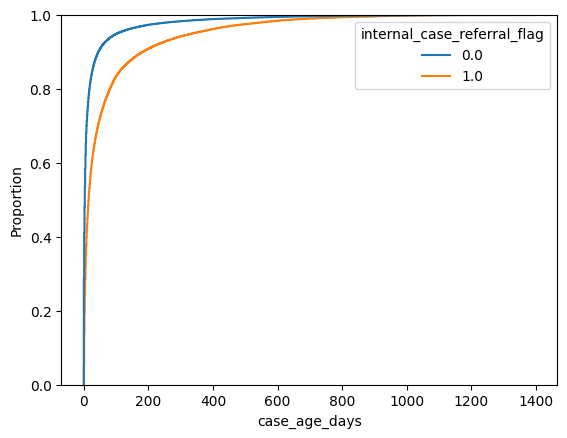

In [12]:
sns.ecdfplot(data=df, x='case_age_days', hue='internal_case_referral_flag')
plt.show()

In [13]:
internal_case_flag = df.loc[(df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag = df.loc[(df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat, p_value = stats.ks_2samp(internal_case_flag, no_case_flag)

print(f'Test statistic: {ks_stat:.3f}, p-value: {p_value:.3e}')

Test statistic: 0.305, p-value: 0.000e+00


We reject the null hypothesis; the test results suggest that the distribution of case ages (in days) are different based on whether they were flagged for internal routing.

In [14]:
# Checking common service category requests 'Parking Violation'
internal_case_flag_pm = df.loc[(df['service_name'] == 'Parking Violation') & (df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag_pm = df.loc[(df['service_name'] == 'Parking Violation') & (df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat_pm, p_val_pm = stats.ks_2samp(internal_case_flag_pm, no_case_flag_pm)

print(f'Test statistic: {ks_stat_pm:.3f}, p-value: {p_val_pm:.3e}')

Test statistic: 0.116, p-value: 4.090e-156


In [15]:
# Checking highly variable service category requests 'Other'
internal_case_flag_other = df.loc[(df['service_name'] == 'Other') & (df['internal_case_referral_flag'] == 1.), 'case_age_days']
no_case_flag_other = df.loc[(df['service_name'] == 'Other') & (df['internal_case_referral_flag'] == 0.), 'case_age_days']
ks_stat_ot, p_val_ot = stats.ks_2samp(internal_case_flag_other, no_case_flag_other)

print(f'Test statistic: {ks_stat_ot:.3f}, p-value: {p_val_ot:.3e}')

Test statistic: 0.609, p-value: 6.423e-322


In [16]:
services = ['Parking Violation', 'Other']
plot_data = df[(df['service_name'].isin(services))].copy()

plot_info = plot_data.groupby(['service_name', 'internal_case_referral_flag'])['case_age_days'].agg(mean='mean', median='median', top_percentile=lambda t: t.quantile(.9)).reset_index()

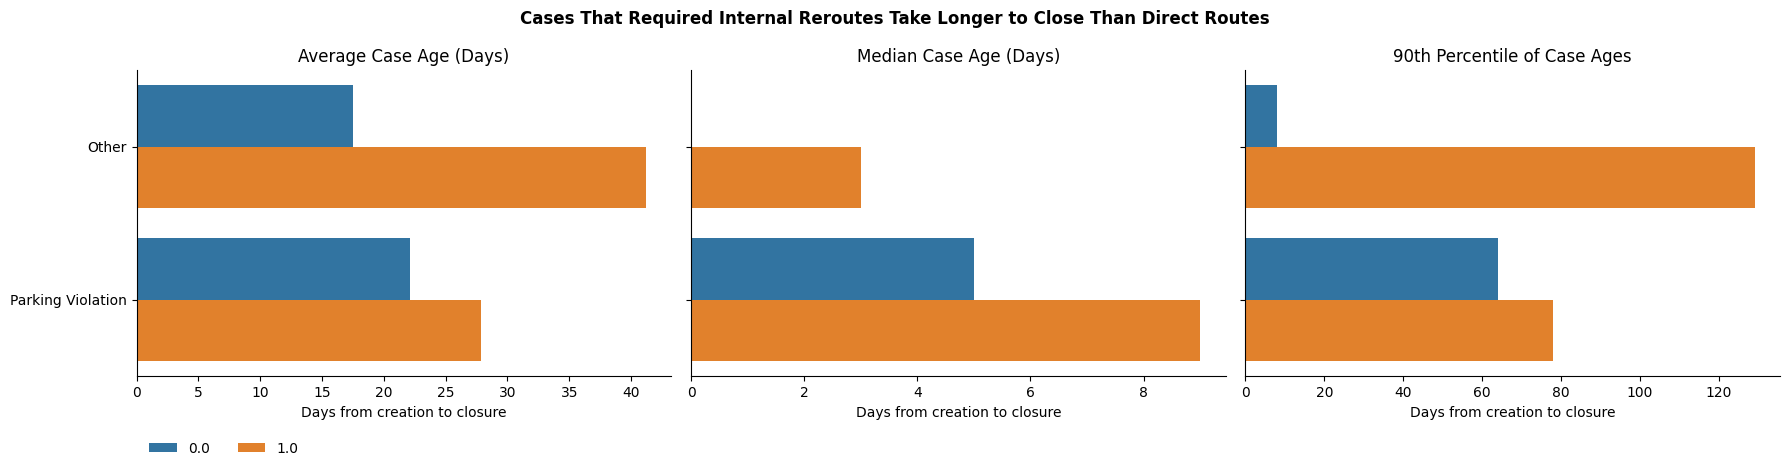

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle('Cases That Required Internal Reroutes Take Longer to Close Than Direct Routes', fontweight='bold')

sns.barplot(data=plot_info, y='service_name', x='mean', hue='internal_case_referral_flag', ax=axes[0])
axes[0].set_title('Average Case Age (Days)')
axes[0].set_xlabel('Days from creation to closure')
axes[0].set_ylabel('')

sns.barplot(data=plot_info, y='service_name', x='median', hue='internal_case_referral_flag', ax=axes[1])
axes[1].set_title('Median Case Age (Days)')
axes[1].set_xlabel('Days from creation to closure')
axes[1].set_ylabel('')

sns.barplot(data=plot_info, y='service_name', x='top_percentile', hue='internal_case_referral_flag', ax=axes[2])
axes[2].set_title('90th Percentile of Case Ages')
axes[2].set_xlabel('Days from creation to closure')
axes[2].set_ylabel('')

# Clean up redundant legends (keep only one on the first plot)
axes[1].get_legend().remove()
axes[2].get_legend().remove()
axes[0].legend(title='', loc='lower left', bbox_to_anchor=(0, -0.3), ncol=2, frameon=False)

# Remove top and right borders (spines) for a cleaner look
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [18]:
day_data = df[(df['internal_case_referral_flag'] == 1.) & (df['internal_referral_count'] >= 0.)]

In [19]:
counts_series = day_data['internal_referral_count'].value_counts()
counts_n_samples = counts_series[counts_series >= 10].index.sort_values()
dunn_data = day_data[day_data['internal_referral_count'].isin(counts_n_samples)]

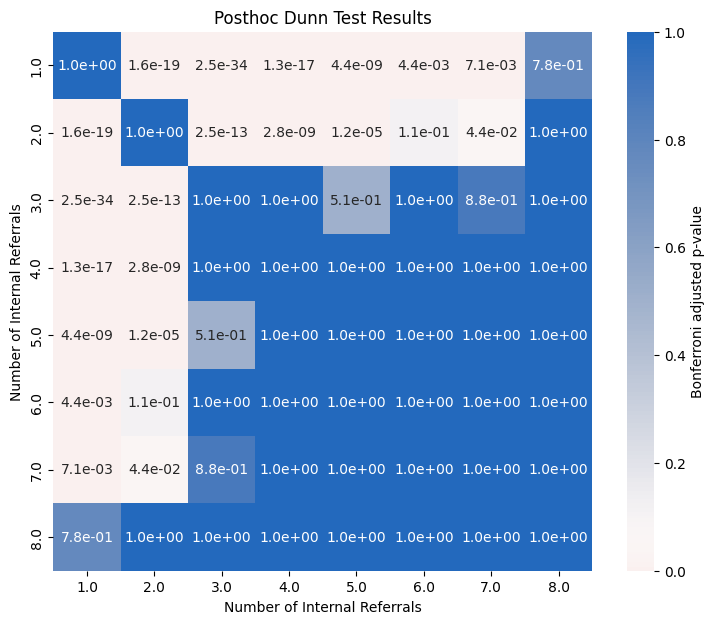

In [20]:
import scikit_posthocs as sp

mat = sp.posthoc_dunn([dunn_data.loc[dunn_data['internal_referral_count'] == c, 'case_age_days'] for c in counts_n_samples], p_adjust='bonferroni')

mat.columns = counts_n_samples
mat.index = counts_n_samples

plt.figure(figsize=(9, 7))
sns.heatmap(mat, annot=True, fmt=".1e", cmap="vlag_r", center=0.05, square=True, vmin=0., vmax=1.0, cbar_kws={'label': 'Bonferroni adjusted p-value'})
plt.title('Posthoc Dunn Test Results')
plt.xlabel('Number of Internal Referrals')
plt.ylabel('Number of Internal Referrals');

In [21]:
counts_series

internal_referral_count
1.0     81053
2.0      7884
3.0      1418
4.0       430
5.0       138
6.0        64
7.0        20
8.0        14
9.0         7
10.0        4
12.0        2
14.0        1
11.0        1
Name: count, dtype: int64

The posthoc Dunn test identifies which pairs of groups (the sample distribution of case ages by number of internal referrals) differ significantly. Many flagged cases require 1-3 internal referrals, so the differences decrease as the number of referrals increase because of small sample sizes or outliers. Still, what is the delay by one internal referral, two referrals, etc.?

In [22]:
table_data = df[df['internal_referral_count'] <= 5].copy()

table_summary = table_data.groupby('internal_referral_count')['case_age_days'].describe().reset_index()

# Calculate the exact delay compared to the 0-referral baseline
baseline_med = table_summary.loc[table_summary['internal_referral_count'] == 0, '50%'].values[0]
baseline_mean = table_summary.loc[table_summary['internal_referral_count'] == 0, 'mean'].values[0]

table_summary['median delays (days)'] = table_summary['50%'] - baseline_med
table_summary['mean delays (days)'] = table_summary['mean'] - baseline_mean

table_summary.round(2)

,internal_referral_count,count,mean,std,min,25%,50%,75%,max,median delays (days),mean delays (days)
0,0.0,1044786.0,28.93,89.81,0.0,1.0,5.0,17.00,1392.0,0.0,0.00
1,1.0,81170.0,64.09,131.47,0.0,3.0,14.0,58.00,1396.0,9.0,35.16
2,2.0,7888.0,73.38,148.81,0.0,5.0,17.0,64.00,1255.0,12.0,44.45
3,3.0,1418.0,99.20,183.27,0.0,7.0,27.0,98.00,1279.0,22.0,70.27
4,4.0,430.0,110.53,180.21,0.0,9.0,35.0,126.75,1097.0,30.0,81.59
5,5.0,139.0,121.24,184.65,0.0,12.0,44.0,140.50,875.0,39.0,92.31


### *What impacts do back-to-back internal handoffs have operationally\*? Do multiple internally routings affect outcomes?

In [23]:
# Mapper dictionary to simplify `case_reason` to `case_outcome` (5 values)

CODEBOOK = {
    "Misrouted indicator": [
        "Send back to intake", "Not a Storm Water Issue", "Not a Storm Water Violation",
        "Complaint Forwarded", "Refer Elsewhere", "Other Department", 
    ],
    "Duplicate": [
        "Duplicate Report", "Duplicate", "ESD Collections - Duplicate reports", 
        "Closed-Duplicate Case", "Close Dups", "Closed-Duplicate"
    ],
    "Gone on arrival / vanished": [
        "GOA", "Gone on Arrival", "Moved", "ESD Collections - Unable to locate", 
        "Unable to locate", "Unable to Locate - SWC", "Moved / Tidied", 
        "Flooding Subsided", "City Contractor Unable to Locate"
    ],
    "Dismissed / non-actionable": [
        "Could not Complete", "Cleared; No Trash", "Do Not Enforce", "No Violation", 
        "Private/Commercial property", "Closed – Insufficient Info", "No Violation Found", 
        "Legally Parked", "Closed-Not Accepted-Budget", "Evaluated; No action warranted",
        "No Discharge", "Non-Stormwater/Private", "City Contractor No Action Taken", 
        "Closed-Administrative Closure", "ESD Collections - Do Not Service", 
        "Insufficient Case Details", "Closed-No violation", "No issue found", "Profanity",
        "No Email", "ESD Collections - Wrong Week", "Delayed Operator Response",
        "Closed Customer", "Private Property", "ESD Collections - Timely Reporting",
        "STRO-More Info Not Provided", "STRO-No Enforcement", "Allowable Discharge",
        "Event In Compliance", "Channel – No Maintenance", "Closed-Void", "Feedback",
        "STRO-Outside City Jurisdiction", "PD Delay", "Known Outreach Area", 
        "Clean Up Denied", "Closed-Due to Budget", "Encampment on Private Property",
        "Request no longer needed", "Cleared Administratively", "Feedback Received",
        "Graffiti - Private", "Unable to contact requestor", "Service Not Provided"
    ],
    "Action taken": [
        "Externally Referred", "Outside City", "Closed-Referral",
        "PD issue not handled in Get It Done", "Problem resolved", "Compliance Achieved", 
        "Container Emptied", "Impounded", "Cleared and Cleaned", "Cited", 
        "Enforcement Action Taken", "Warned", "Issue Resolved", "City Contractor Resolved", 
        "Closed-Involuntary Compliance", "Problem Abated", "Repaired by City", 
        "Container Removed", "Contact Made", "Request for Resurfacing", "PUD SN Created",
        "Cleared - ESD Cleanup Pending", "Customer Contacted", "Service Provider",
        "Resolved", "Assigned to User", "Closed-Voluntary Compliance",
        "Pending coordination", "Case Open in Accela", "Projects queue", "Revisit",
        "Crew Job Submitted", "Community Relations Officer", "Complete", "Planned Work",
        "Problem Fixed", "STRO-Noise Complaint (People)", "Investigation (Non-Stormw Asset)",
        "Temporary repair", "Provided requested information", "Marked for 72 Hour",
        "Channel – Minor", "Closed-Alternative Compliance", 
        "STRO-Host or Guest Conflict (NCRC)", "Enforcement Feedback", 
        "Active Investigation", "Clean Up Completed", "Sweeping request (Non-Emergency)",
        "Completed", "Blockage Removed", "Closed-Nuisance Referral", "Closed-Referred",
        "Litter", "Encampment on City Property or ROW", "ESD Cleanup", "TED Request Needed"
    ]
}

In [24]:
outcome_palette = {
    'Action taken': '#006989',
    'Gone on arrival / vanished': '#C45700',
    'Duplicate': '#F18F01',
    'Misrouted indicator': '#FFB85C',
    'Dismissed / non-actionable': '#FFEED6'
}

In [25]:
# NO_ACTION = ["Duplicate", "Gone on arrival / vanished", "Dismissed / non-actionable"]
reason_map = {reason: keys for keys, vals in CODEBOOK.items() for reason in vals}

df['case_outcome'] = df['case_reason'].map(reason_map)

In [26]:
counts = day_data['internal_referral_count'].value_counts()
counts_n_samples = counts[counts >= 30].index.sort_values()
data2 = df[(df['internal_case_referral_flag'] == 1.) & (df['internal_referral_count'].notna()) & (df['internal_referral_count'] > 0) & (df['internal_referral_count'].isin(counts_n_samples))]

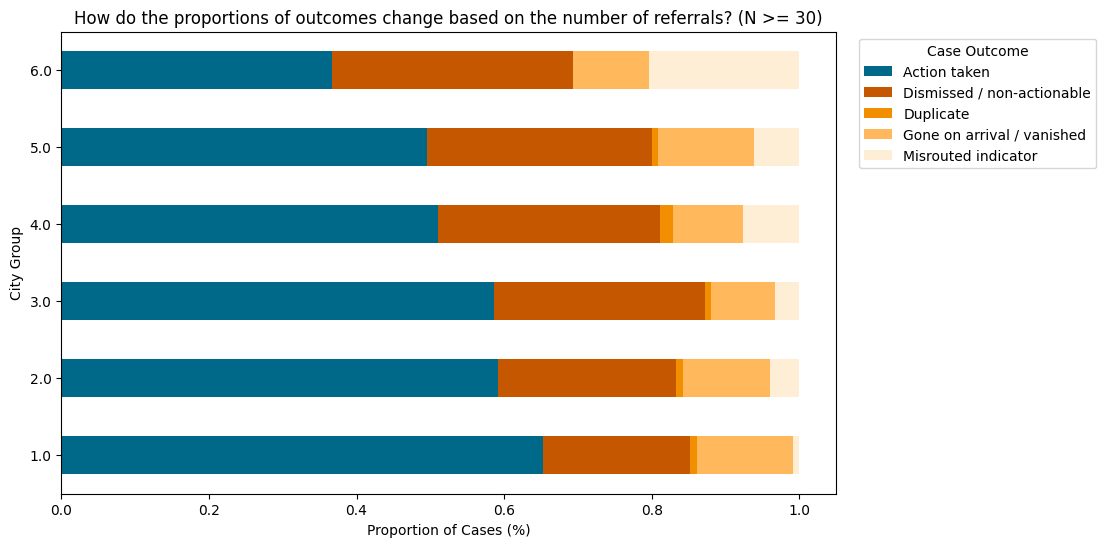

In [27]:
plot_data2 = data2.groupby('internal_referral_count')['case_outcome'].value_counts(normalize=True).unstack()
fig, ax = plt.subplots(figsize=(10, max(6, len(plot_data2) * 0.4)))
plot_data2.plot(kind='barh', stacked=True, ax=ax, linewidth=0.5, color=[outcome_palette[c] for c in outcome_palette])
ax.set_title('How do the proportions of outcomes change based on the number of referrals? (N >= 30)')
ax.set_xlabel('Proportion of Cases (%)')
ax.set_ylabel('City Group')
plt.legend(title='Case Outcome', bbox_to_anchor=(1.02, 1), loc='upper left');

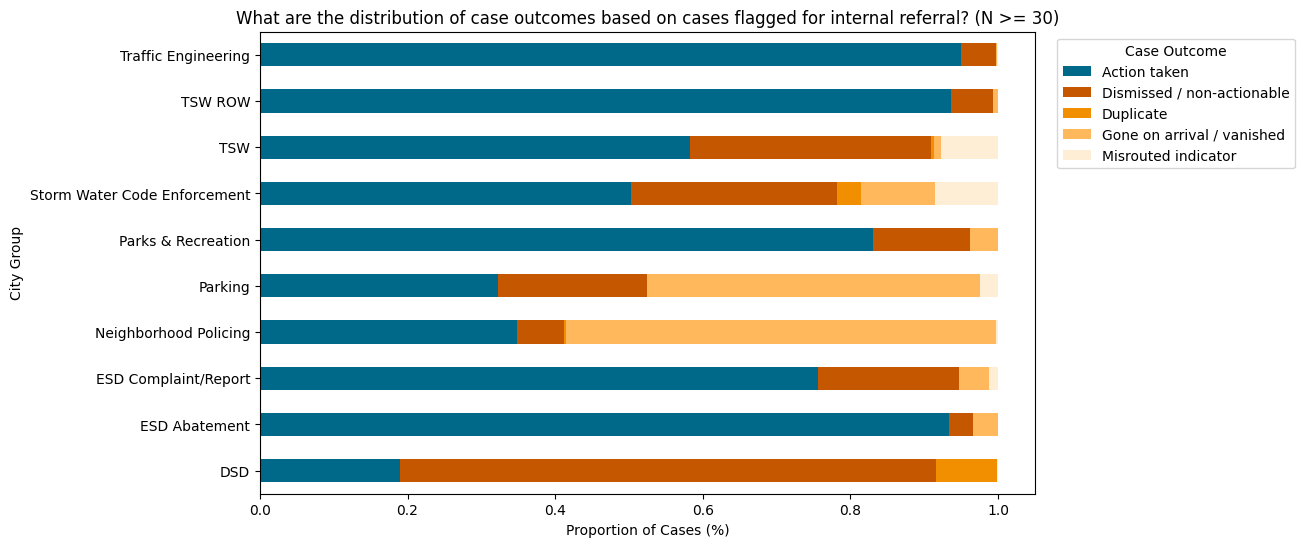

In [28]:
plot_data3 = (
    data2[data2['case_record_type'].isin(data2['case_record_type'].value_counts().index[:-1])]
    .groupby('case_record_type')['case_outcome']
    .value_counts(normalize=True)
    .unstack()
    )
fig, ax = plt.subplots(figsize=(10, max(6, len(plot_data3) * 0.4)))
plot_data3.plot(kind='barh', stacked=True, ax=ax, linewidth=0.5, color=[outcome_palette[c] for c in outcome_palette])
ax.set_title('What are the distribution of case outcomes based on cases flagged for internal referral? (N >= 30)')
ax.set_xlabel('Proportion of Cases (%)')
ax.set_ylabel('City Group')
plt.legend(title='Case Outcome', bbox_to_anchor=(1.02, 1), loc='upper left');

> Are internal referrals tied to specific service categories?

In [29]:
service_counts = df['service_name'].value_counts()
contingency_table = pd.crosstab(df.loc[df['service_name'].isin(service_counts[service_counts >= 30].index), 'service_name'], df.loc[df['service_name'].isin(service_counts[service_counts >= 30].index), 'internal_case_referral_flag'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f'Test statistic: {chi2_stat:.3f}, p-value: {p_val:.3e}, DOF: {dof}')

Test statistic: 250683.698, p-value: 0.000e+00, DOF: 37


We reject the null: specific categories are likely to be flagged for internal referrals.

> Does the number of internal referrals affect the case outcome?

In [30]:
contingency_table = pd.crosstab(df.loc[df['internal_referral_count'].isin(counts_n_samples), 'internal_referral_count'], df.loc[df['internal_referral_count'].isin(counts_n_samples), 'case_outcome'])
chi2_stat, p_val, dof, expected = stats.chi2_contingency(contingency_table)
print(f'Test statistic: {chi2_stat:.3f}, p-value: {p_val:.3e}, DOF: {dof}')

Test statistic: 987.992, p-value: 1.419e-196, DOF: 20


This result implies that the number of internal referrals are associated with case outcomes.

<!-- If internal referrals are also related response/service delays, then this delay (in ages) means the case outcome, upon arrival, may change within this timeframe. -->

1. What does an internal referral count of 1.0 actually mean? Are these cases initially misrouted and require a transfer to another department?